<a href="https://colab.research.google.com/github/Finglers-Tinglin/mining-data/blob/main/Final_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

''' For instructor information, Hybrid 05 is answered under the section titled 'Data Visualization for Hybrid 05' '''

# Plotting the theme and importing the file, displaying it to get an idea of what's going on
sns.set_theme(style="darkgrid", context="notebook", palette="autumn")
plt.rcParams.update({"figure.dpi": 115, "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 20)

df = pd.read_csv("production.csv")
df.head()

,Mineral,States,Unit,Quantity 2010-11,Value 2010-11,Quantity 2011-12,Value 2011-12,Quantity 2012-13,Value 2012-13,Quantity 2013-14,Value 2013-14,Quantity 2014-15(P),Value 2014-15(P)
0,Coal,India,000tonne,532694.0,620210400.0,539950.0,701719100.0,556402.0,747186600.0,565765.0,825347500.0,610208.0,891754480.0
1,Coal,Andhra Pradesh,000tonne,51333.0,81106100.0,52211.0,90008100.0,53190.0,91695800.0,50469.0,73998000.0,0.0,0.0
2,Coal,Arunachal Pradesh,000tonne,299.0,1106000.0,221.0,1464100.0,73.0,483600.0,0.0,0.0,0.0,0.0
3,Coal,Assam,000tonne,1101.0,4072600.0,602.0,3988000.0,605.0,3591200.0,664.0,3392900.0,767.0,3919209.0
4,Coal,Chhattisgarh,000tonne,113824.0,58256200.0,113958.0,70740300.0,117830.0,90750700.0,127095.0,89275000.0,134396.0,94403380.0


In [2]:
# Initial EDA, necessary before we can visualize anything
print("COLUMN TYPES")
print(df.dtypes.to_string())
print("\nMISSING VALUES")
print(df.isna().sum().to_string())
print("\nDIRTY NUMERICAL SUMMARY")
display(df.describe().round(2))
print("UNIT TYPES")
display(df["Unit"].value_counts())

COLUMN TYPES
Mineral                 object
States                  object
Unit                    object
Quantity 2010-11       float64
Value 2010-11          float64
Quantity 2011-12       float64
Value 2011-12          float64
Quantity 2012-13       float64
Value 2012-13          float64
Quantity 2013-14       float64
Value 2013-14          float64
Quantity 2014-15(P)    float64
Value 2014-15(P)       float64

MISSING VALUES
Mineral                 0
States                  0
Unit                    0
Quantity 2010-11        8
Value 2010-11           8
Quantity 2011-12       10
Value 2011-12          10
Quantity 2012-13        9
Value 2012-13           9
Quantity 2013-14        5
Value 2013-14           4
Quantity 2014-15(P)    10
Value 2014-15(P)       10

NUMERICAL SUMMARY


,Quantity 2010-11,Value 2010-11,Quantity 2011-12,Value 2011-12,Quantity 2012-13,Value 2012-13,Quantity 2013-14,Value 2013-14,Quantity 2014-15(P),Value 2014-15(P)
count,444.00,4.440000e+02,442.00,4.420000e+02,443.00,4.430000e+02,447.00,4.480000e+02,442.00,4.420000e+02
mean,348122.24,9.982810e+06,367802.52,1.050175e+07,403795.41,1.053369e+07,413755.96,1.055236e+07,389940.71,1.070379e+07
std,1101604.28,5.720958e+07,1136155.42,5.914618e+07,1284065.51,5.922980e+07,1500567.97,6.073683e+07,1474265.23,6.268764e+07
min,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
25%,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
50%,8607.00,8.792500e+03,9911.50,1.202250e+04,8593.00,1.355200e+04,10066.00,1.198550e+04,7462.50,1.384900e+04
75%,132748.75,2.092112e+05,126495.75,2.590230e+05,129194.50,3.545935e+05,141392.00,3.654680e+05,120028.00,3.447135e+05
max,12722820.00,6.880413e+08,13599566.00,7.017191e+08,16611610.00,7.471866e+08,22319148.00,8.253475e+08,22226062.00,8.917545e+08


UNIT TYPES


,count
Unit,
tonne,351
000tonne,65
kg,22
m c m,10
crt,4


In [3]:
# We want to further investigate the data and proceed with cleaning it by standardizing it first
print("\nUnique States:", sorted(df['States'].unique()))
print("Unique Units:", df['Unit'].unique())



Unique States: ['Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'India', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Off-shore', 'Orissa', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Tamilnadu', 'Telangana', 'Telangana*', 'Tripura', 'Uttar Pradesh', 'Uttaranchal', 'West Bengal']
Unique Units: ['000tonne' 'm c m' 'tonne' 'kg' 'crt']


Data cleaning will address three issues in this dataset:
1. **Missing Values:** 2.5% of our data contains missing values. This is not significant enough to impute, so we're dropping the data.
2. **Location Standardization:** Unified duplicate and inconsistently formatted state names.
3. **Mixed Granularity:** Removed aggregate national level rows labeled "India" so they don't taint our data especially in visualization.

In [4]:
# Start by standardizing names, stripping whitespace, trailing asterisks, and spelling variance
df['States'] = (
    df['States'].str.strip().str.replace(r'\*+$', '', regex=True) # Strips trailing asterisks
    .replace({'Tamilnadu': 'Tamil Nadu'}) # Replaces instances of 'Tamilnadu' with 'Tamil Nadu'
)

# Next we should resolve mixed granularity by separating aggregate national totals from what should be state records
df_national = df[df['States'] == 'India'].copy() # We save this copy because it will be prudent to explore later
df_states = df[df['States'] != 'India'].copy()

# Now we need to address missing values via listwise deletion on state-level data
production_cols = [c for c in df_states.columns if 'Quantity' in c or 'Value' in c]
df_clean = df_states.dropna(subset=production_cols).copy()

# Now we can verify cleanliness by printing
print(f"Original records: {len(df)}")
print(f"National aggregate records isolated: {len(df_national)}")
print(f"Cleaned state-level records remaining: {len(df_clean)}")
print(f"\nRemaining missing values in clean dataset:\n{df_clean[production_cols].isna().sum()}")

Original records: 452
National aggregate records isolated: 75
Cleaned state-level records remaining: 358

Remaining missing values in clean dataset:
Quantity 2010-11       0
Value 2010-11          0
Quantity 2011-12       0
Value 2011-12          0
Quantity 2012-13       0
Value 2012-13          0
Quantity 2013-14       0
Value 2013-14          0
Quantity 2014-15(P)    0
Value 2014-15(P)       0
dtype: int64


In [8]:
# Now that we have clean data we should check to see how, and if, the data has changed
print("\nCLEAN NUMERICAL SUMMARY")
display(df_clean.describe().round(2))


CLEAN NUMERICAL SUMMARY


,Quantity 2010-11,Value 2010-11,Quantity 2011-12,Value 2011-12,Quantity 2012-13,Value 2012-13,Quantity 2013-14,Value 2013-14,Quantity 2014-15(P),Value 2014-15(P)
count,358.00,3.580000e+02,358.00,3.580000e+02,358.00,3.580000e+02,358.00,3.580000e+02,358.00,3.580000e+02
mean,215768.66,6.190368e+06,227048.13,6.482907e+06,249834.31,6.517350e+06,255336.98,6.601380e+06,237678.18,6.391346e+06
std,710142.11,3.127419e+07,712328.06,3.063447e+07,779104.06,3.014886e+07,881452.96,3.068711e+07,865883.15,3.092679e+07
min,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
25%,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00,0.00,0.000000e+00
50%,6005.00,6.289000e+03,6751.00,9.084500e+03,7006.00,1.179100e+04,7302.00,9.664500e+03,4711.00,8.547500e+03
75%,64174.00,1.633468e+05,82870.00,1.811638e+05,86016.25,2.490225e+05,86784.75,2.521798e+05,78644.25,2.115582e+05
max,7539999.00,3.880776e+08,8041881.00,3.645036e+08,8633411.00,3.348159e+08,9281807.00,3.308536e+08,9346349.00,3.440129e+08


# Data Visualization

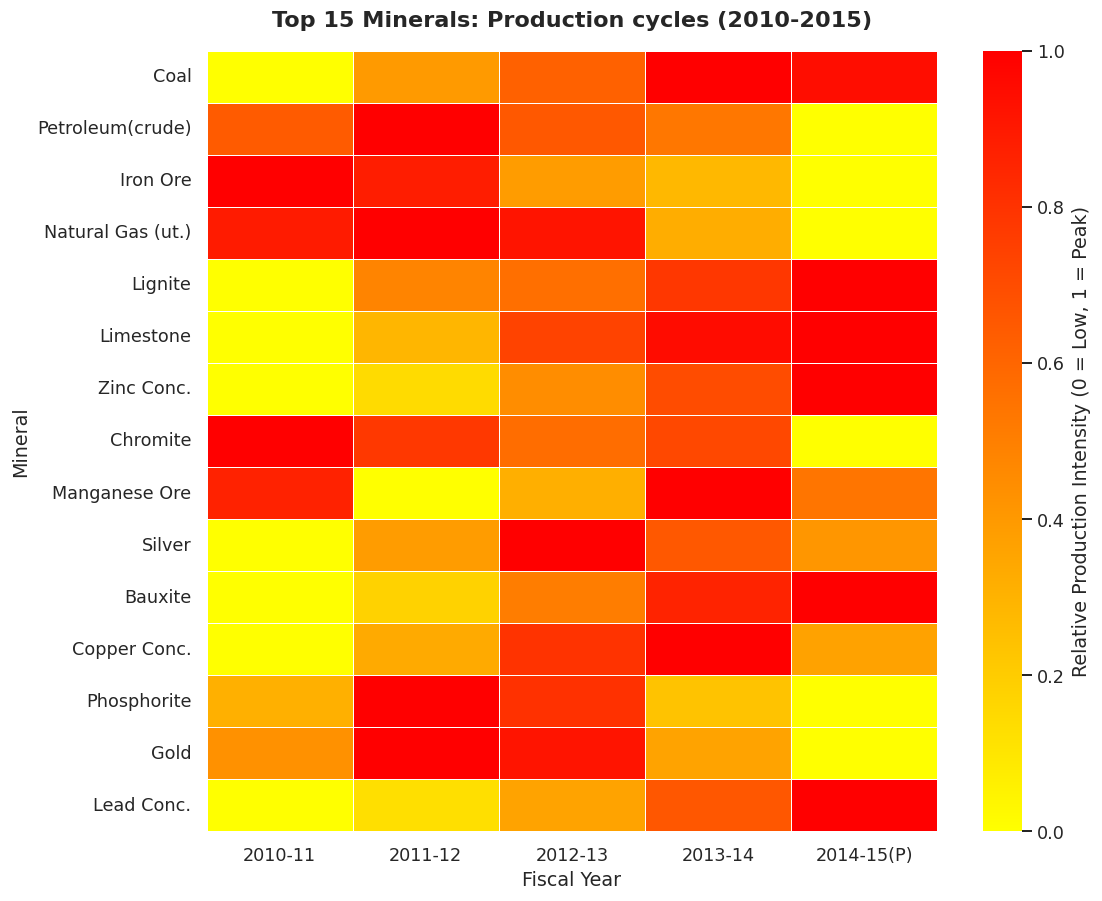

In [5]:
# We should aggregate national total values per mineral per year
val_cols = [c for c in df_clean.columns if c.startswith('Value')]
clean_years = [c.replace('Value ', '') for c in val_cols]

# Sum total value across all states by mineral
mineral_val = df_clean.groupby('Mineral')[val_cols].sum()
mineral_val.columns = clean_years

# Select top 15 highest-value minerals to keep the visual readable
top_minerals = mineral_val.sum(axis=1).nlargest(15).index
heatmap_data = mineral_val.loc[top_minerals]

# Normalize each row (min-max scaling per mineral) to show relative growth/cooling cycles
heatmap_norm = heatmap_data.apply(lambda row: (row - row.min()) / (row.max() - row.min() + 1e-9), axis=1)

# Draw
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_norm, cmap='autumn_r', annot=False, linewidths=0.5,cbar_kws={'label': 'Relative Production Intensity (0 = Low, 1 = Peak)'})
plt.title('Top 15 Minerals: Production cycles (2010-2015)', fontsize=14, pad=15)
plt.xlabel('Fiscal Year', fontsize=12)
plt.ylabel('Mineral', fontsize=12)
plt.tight_layout()
plt.show()

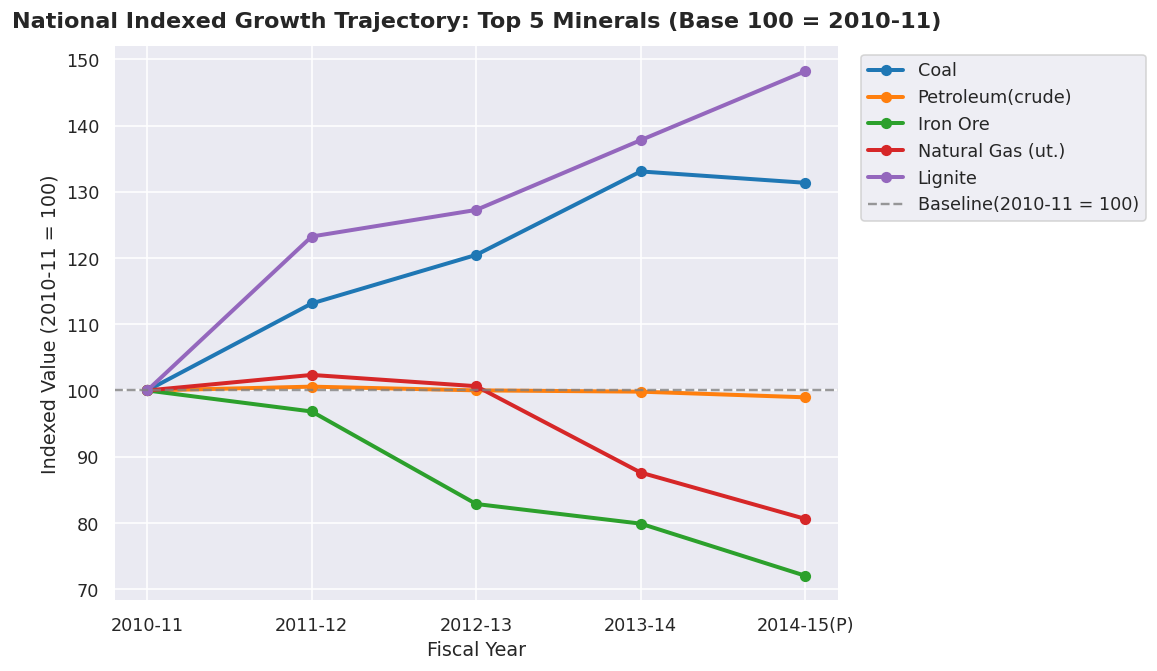

In [6]:
# Next, our indexed growth trendlines for our top commodities
# Select top 5 minerals by overall national economic value
top_5_minerals = mineral_val.sum(axis=1).nlargest(5).index
top_5_data = mineral_val.loc[top_5_minerals]

# Index to base 100 starting in 2010-11
base_year = clean_years[0]
indexed_growth = top_5_data.div(top_5_data[base_year], axis=0) * 100

# The color palette needs to change for this visualization
plt.figure(figsize=(10, 6))
distinct_colors = sns.color_palette("tab10", len(top_5_minerals))

# Plot trendlines
for mineral, color in zip(top_5_minerals, distinct_colors):
  plt.plot(clean_years, indexed_growth.loc[mineral], marker='o', linewidth=2.5, label=mineral, color=color)

plt.axhline(100, color='gray', linestyle='--', alpha=0.8, label='Baseline(2010-11 = 100)')
plt.title('National Indexed Growth Trajectory: Top 5 Minerals (Base 100 = 2010-11)', fontsize=14, pad=12)
plt.xlabel('Fiscal Year', fontsize=12)
plt.ylabel('Indexed Value (2010-11 = 100)', fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

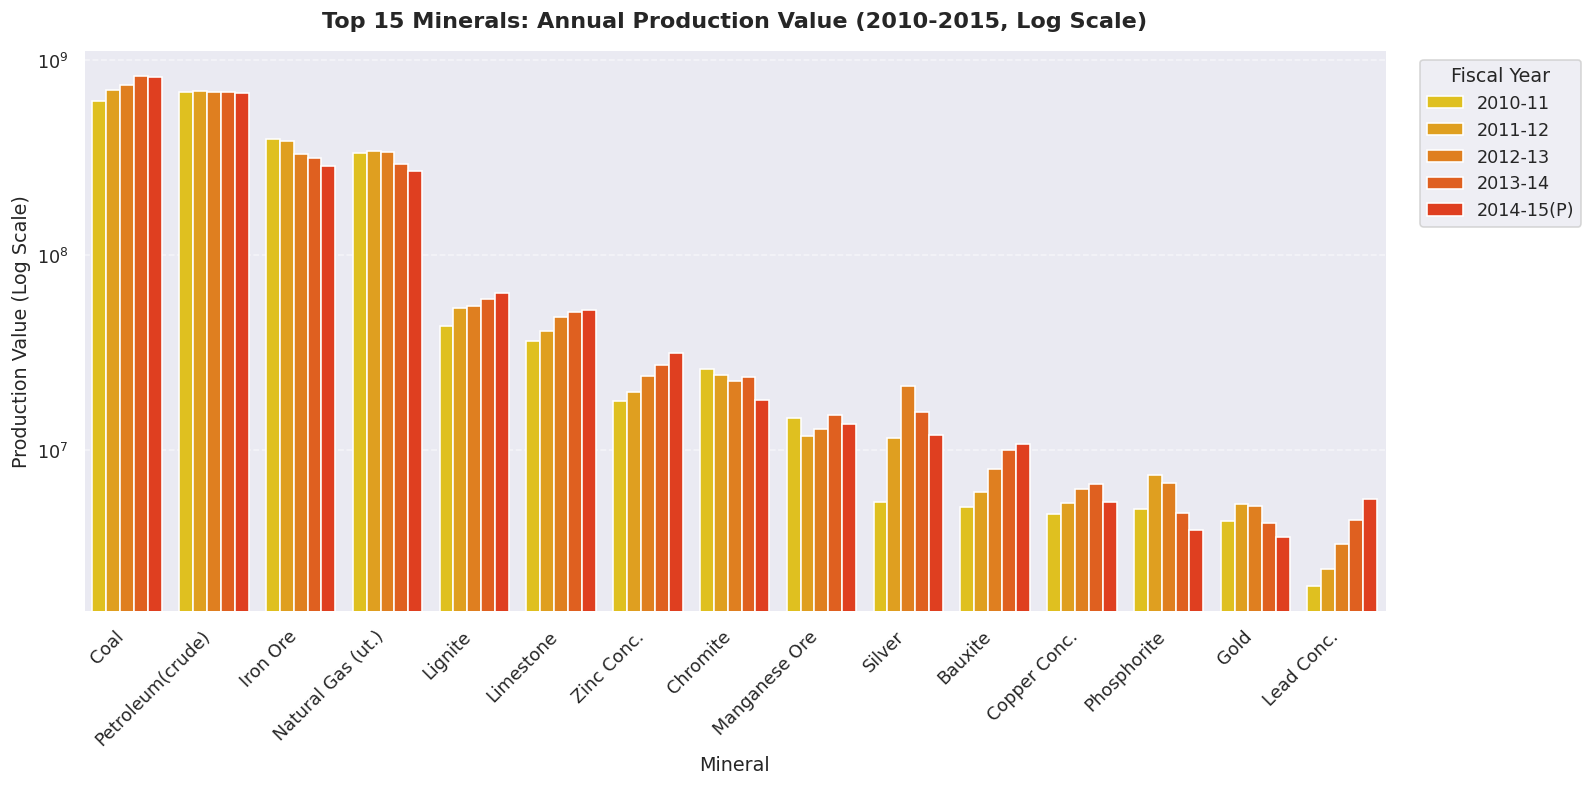

In [10]:
# Grouped bar chart by fiscal year on a log scale
# First, select the top 15 highest value resources
top_minerals = mineral_val.sum(axis=1).nlargest(15).index
top_15_df = mineral_val.loc[top_minerals]

# Next, reshape the chart and replace 0's with NaN so the log axis doesn't break
long_df = top_15_df.reset_index().melt(
    id_vars='Mineral',
    var_name='Fiscal Year',
    value_name='Value'
)
long_df['Value'] = long_df['Value'].replace(0,np.nan)

plt.figure(figsize=(14,7))
sns.barplot(
    data=long_df,
    x='Mineral',
    y='Value',
    hue='Fiscal Year',
    palette='autumn_r'
)

plt.yscale('log')
plt.title('Top 15 Minerals: Annual Production Value (2010-2015, Log Scale)', fontsize=14, pad=15)
plt.xlabel('Mineral', fontsize=12)
plt.ylabel('Production Value (Log Scale)', fontsize=12)
plt.xticks(rotation=45,ha='right')
plt.legend(title='Fiscal Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(axis='y',linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()